<a href="https://colab.research.google.com/github/aykut-gumus/AI-dev-bootcamp/blob/main/Oturum_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Yapay Nöron

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
np.random.seed(42)

Bir öğrencinin haftalık çalışma saati ve günlük çalışma saatinden sınavı geçme olasılığını tahmin eden bir nöron. Ağırlıkları şimdilik biz veriyoruz.

### Tek Nöron

In [3]:
x = np.array([10,7])

w = np.array([0.4,0.3])
b = -5

z = np.dot(w,x) + b

In [4]:
a = 1 / (1+np.exp(-z))

In [5]:
print("Ağırlıklı toplam z :" , round(z,2))

Ağırlıklı toplam z : 1.1


In [6]:
print("Nöronun çıktısı a :" , round(a,2))

Nöronun çıktısı a : 0.75


### Çoklu Nöron

In [7]:
x = np.array([10,7])

w = np.array([[0.4,-0.2,0.1],
              [0.3,0.5,-0.1]
              ])
b = np.array([-5,-1,0])

z = x @ w + b

In [8]:
a = 1 / (1+np.exp(-z))

In [9]:
print("Ağırlık matrisinin boyutu : " , w.shape)
print("Katmanın toplamları z : " , np.round(z,2))
print("Katmanın çıktıları a : " , np.round(a,2))

Ağırlık matrisinin boyutu :  (2, 3)
Katmanın toplamları z :  [1.1 0.5 0.3]
Katmanın çıktıları a :  [0.75 0.62 0.57]


In [12]:
import keras

(X_egitim, y_egitim), (X_test, y_test) = keras.datasets.mnist.load_data()

print("Eğitim verileri : ", X_egitim.shape)

Eğitim verileri :  (60000, 28, 28)


In [13]:
X_egitim = X_egitim / 255
X_test = X_test / 255

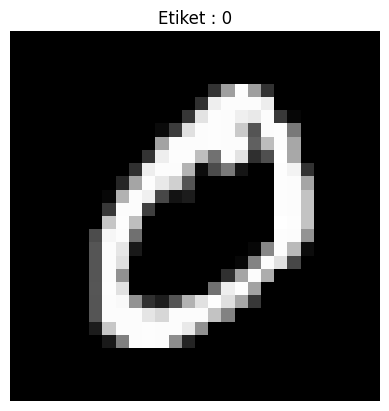

In [14]:
plt.imshow(
    X_egitim[1],
    cmap="gray"
)
plt.title('Etiket : ' + str(y_egitim[1]))
plt.axis('off')
plt.show()

# Model Oluşturulması

In [15]:
model = keras.Sequential([
    keras.Input(shape=(28,28)),
    keras.layers.Flatten(),
    keras.layers.Dense(
        128,
        activation='relu'
      ),
    keras.layers.Dense(
        10,
        activation='softmax'
      ),
    ])

In [16]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [17]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [18]:
model.fit(X_egitim, y_egitim, epochs=3, batch_size=128, validation_split=0.1)

Epoch 1/3
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.8961 - loss: 0.3763 - val_accuracy: 0.9548 - val_loss: 0.1673
Epoch 2/3
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9497 - loss: 0.1747 - val_accuracy: 0.9662 - val_loss: 0.1197
Epoch 3/3
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9647 - loss: 0.1258 - val_accuracy: 0.9728 - val_loss: 0.1027


In [19]:
kayip, dogruluk = model.evaluate(
    X_test,
    y_test,
    verbose = 0
    )

In [20]:
print("Test doğruluğu : %" , round(dogruluk * 100,1))

Test doğruluğu : % 96.5
